# **Prepare Data**

**C1**. Data-quality problems and treatment

In [ ]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Loaded file:", filename)
print("Original dataset shape:", df.shape)
display(df.head())


Saving WA_Fn-UseC_-Telco-Customer-Churn (1).csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Loaded file: WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Original dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace(r"^\\s*$", np.nan, regex=True)

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Column names:")
print(df.columns.tolist())
print("\\nData types and non-null counts:")
display(df.info())


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9  

None

In [ ]:
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)

print("Missing values by column:")
display(missing_report)

duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

df = df.drop_duplicates().copy()
print("Shape after removing exact duplicates:", df.shape)


Missing values by column:


,Missing Count,Missing Percent
TotalCharges,11,0.16
gender,0,0.00
SeniorCitizen,0,0.00
Partner,0,0.00
customerID,0,0.00
Dependents,0,0.00
tenure,0,0.00
MultipleLines,0,0.00
PhoneService,0,0.00
OnlineSecurity,0,0.00


Exact duplicate rows: 0
Shape after removing exact duplicates: (7043, 21)


In [ ]:
checks = {}

if "tenure" in df.columns:
    checks["tenure outside 0–1000 months"] = ((df["tenure"] < 0) | (df["tenure"] > 1000)).sum()

if "MonthlyCharges" in df.columns:
    checks["negative MonthlyCharges"] = (df["MonthlyCharges"] < 0).sum()

if "TotalCharges" in df.columns:
    checks["negative TotalCharges"] = (df["TotalCharges"] < 0).sum()

if "Churn" in df.columns:
    checks["Churn values outside Yes/No"] = (~df["Churn"].isin(["Yes", "No"])).sum()

print("Unexpected-value checks:")
display(pd.Series(checks, name="Count").to_frame())

print("Numeric summary:")
display(df.select_dtypes(include=np.number).describe().T)


Unexpected-value checks:


,Count
tenure outside 0–1000 months,0
negative MonthlyCharges,0
negative TotalCharges,0
Churn values outside Yes/No,0


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


**C2**. Train/test split

In [ ]:
TARGET = "Churn"

if TARGET not in df.columns:
    raise ValueError("The uploaded dataset must contain a 'Churn' column.")

df = df[df[TARGET].isin(["Yes", "No"])].copy()

y = df[TARGET].map({"No": 0, "Yes": 1})
X = df.drop(columns=[TARGET])

if "customerID" in X.columns:
    X = X.drop(columns=["customerID"])

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\\nChurn proportion in full data:")
display(y.value_counts(normalize=True).rename("Proportion").to_frame())
print("\\nChurn proportion in training data:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())
print("\\nChurn proportion in testing data:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())


Training rows: 5634
Testing rows: 1409
\nChurn proportion in full data:


,Proportion
Churn,
0,0.73463
1,0.26537


\nChurn proportion in training data:


,Proportion
Churn,
0,0.734647
1,0.265353


\nChurn proportion in testing data:


,Proportion
Churn,
0,0.734564
1,0.265436


**C3**. Data-learned preparation steps and leakage prevention


In [ ]:


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("C3: Preprocessing pipeline completed!")
print("Imputation and encoding learned from training data only.")


C3: Preprocessing pipeline completed!
Imputation and encoding learned from training data only.


**C4**. Features removed or retained

In [ ]:

print("Original Features:")
print(df.drop(columns=["Churn"]).columns.tolist())

if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("\nRemoved Feature:")
print("customerID - Identifier only")

print("\nRetained Features:")
for feature in X.columns:
    print("-", feature)

print("\nTotal Retained Features:", X.shape[1])

print("\nNew Features Created: None")


Original Features:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Removed Feature:
customerID - Identifier only

Retained Features:
- gender
- SeniorCitizen
- Partner
- Dependents
- tenure
- PhoneService
- MultipleLines
- InternetService
- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies
- Contract
- PaperlessBilling
- PaymentMethod
- MonthlyCharges
- TotalCharges

Total Retained Features: 19

New Features Created: None


**C5**. Transformations and algorithm choice

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocess, numeric_features),
        ("categorical", categorical_preprocess, categorical_features)
    ],
    remainder="drop"
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Total input features:", X_train.shape[1])


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Total input features: 19


**C6**. Feature availability at prediction time

,Metric,Score
0,Recall (primary),0.4652
1,F1-score,0.5305
2,ROC-AUC,0.8224
3,Accuracy,0.7814
4,Precision,0.6170


\nClassification report:
              precision    recall  f1-score   support

    No Churn       0.82      0.90      0.86      1035
       Churn       0.62      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



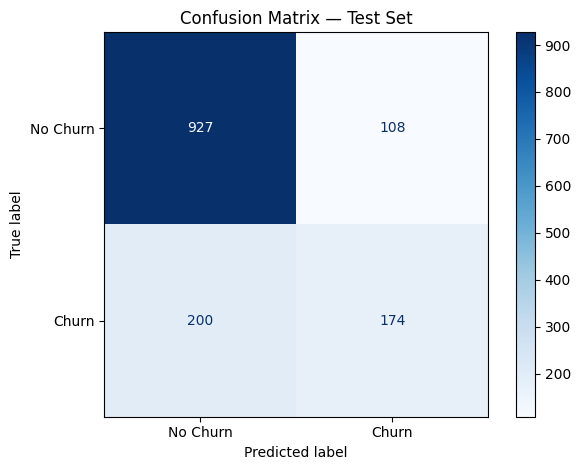

In [ ]:
model.fit(X_train, y_train)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Metric": ["Recall (primary)", "F1-score", "ROC-AUC", "Accuracy", "Precision"],
    "Score": [
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob),
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0)
    ]
})

display(results.round(4))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()
